# deliberation allocation: Comparison with published methods

**Level:** 3 **Prerequisites:** Deliberation allocation level 1 **Reading time:** 25 minutes

**Question:** Does the measured XGBoost comparator provide a stronger case-level result than this delegation sample?

## Objectives

This lesson investigates the question: Does the measured XGBoost comparator provide a stronger case-level result than this delegation sample?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/semantic-routing-study/analysis; - `data/derived/episodes/M11-C13-nominal-40000; - `data/derived/episodes/M12-C13-nominal-40000; - `data/derived/episodes/M09-C13-nominal-40000; - `data/derived/episodes/M10-C13-nominal-40000;json`

## Method

Value-of-computation and learning-to-defer research formalize whether another computation is worth its cost. The relevant quantities include expected incremental utility, planner delay, invalid response probability and whether the result arrives before the state changes. Neuraxis's fitted gates never delegated at the selected threshold, and this negative result is retained. M04 provides an executed learned-policy comparison on the same C13 task; it is not itself a planner. A configured Ollama call would be a separate measurement and is not synthesized from frozen planner traces. A fair allocation experiment pairs fast-only and delegated runs on the same observation, tools and task contract, then records decision quality and wall-clock cost as separate outcomes. Positive gate examples must include cases where deliberation changes a consequential choice; otherwise a learned gate can minimize loss by never delegating and appear successful without learning allocation. A large language model is a stochastic external component, so its model identity, prompt, decoding settings, timeout behavior and invalid-output handling belong in the experiment record. A useful extension introduces ambiguous observations with positive delegation value and negative controls where the fast policy is already sufficient.

### deliberation allocation · level 3 | Verify the audit and each trace's bytes before interpreting outcomes.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M11', 'M12', 'M04']
sample_case, seed = 'C13', 40000
evidence = load_lesson_evidence(
    ROOT, topic='04-deliberation-allocation', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 3 | case variants: 18


### Compare methods across variants: never infer learned allocation from a method name.

### deliberation allocation · level 3 | Execute the released policies and compare the run

### deliberation allocation · level 3 | Compare the full sequence, not only the first action

### deliberation allocation · level 3 | Recompute per-variant outcomes from every trace in the case

In [3]:
# Read every seed for the selected case and keep each failed episode in the denominator.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M04 boundary successes= 10 episodes= 10 rate= 1.0
M04 delayed_observation successes= 10 episodes= 10 rate= 1.0
M04 duplicate_event successes= 10 episodes= 10 rate= 1.0
M04 nominal successes= 10 episodes= 10 rate= 1.0
M04 stale_conflict successes= 10 episodes= 10 rate= 1.0
M04 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M11 boundary successes= 10 episodes= 10 rate= 1.0
M11 delayed_observation successes= 10 episodes= 10 rate= 1.0
M11 duplicate_event successes= 10 episodes= 10 rate= 1.0
M11 nominal successes= 10 episodes= 10 rate= 1.0
M11 stale_conflict successes= 10 episodes= 10 rate= 1.0
M11 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M12 boundary successes= 10 episodes= 10 rate= 1.0
M12 delayed_observation successes= 10 episodes= 10 rate= 1.0
M12 duplicate_event successes= 10 episodes= 10 rate= 1.0
M12 nominal successes= 10 episodes= 10 rate= 1.0
M12 stale_conflict successes= 10 episodes= 10 rate= 1.0
M12 unavailable_dependency successes= 10 episodes= 10

### Plot the variant stress without pooling families

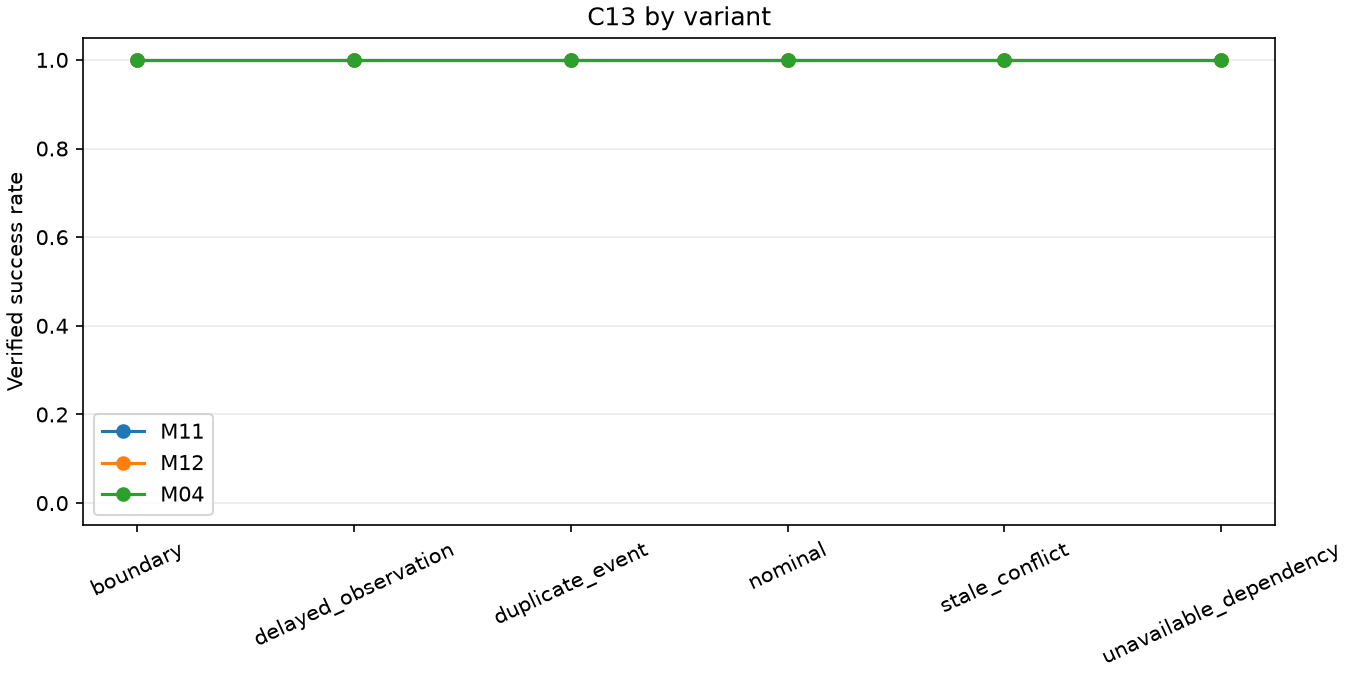

In [4]:
# Each point summarizes the seeds from one case variant, not the full benchmark.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified success rate")
ax.set_title(sample_case + " by variant")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


A fitted routing label is not a completed task; inspect the policy's measured result. For chart 1, the denominator is the manifest-hash-verified C13 episode slice loaded above, and failed outcomes remain included. Chart 1 describes the C13 task family not real-world incident rates or unseen software performance. Interpret chart 1 for C13 with its trace and verified postcondition before calling a visual difference a control improvement.

In [5]:
# This offline experiment is never pooled with the core benchmark.
routing = json.loads((ROOT / "data/derived/semantic-routing-study/analysis.json").read_text(encoding="utf-8"))
print(
    "threshold=",
    routing["selected_threshold"],
    "| fit positives=",
    routing["fit_positives"],
    "| calibration positives=",
    routing["calibration_positives"],
)
for arm, result in routing["test"].items():
    print(arm, result)


threshold= 0.44629505030857797 | fit positives= 19 | calibration positives= 8
always_fast_M04 {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
always_planner_M09 {'episodes': 32, 'invalid_policy_outputs': 8, 'mean_wall_ms': 20052.693393749905, 'planner_episodes': 32, 'verified_successes': 10}
hash_half {'episodes': 32, 'invalid_policy_outputs': 4, 'mean_wall_ms': 11568.068874998971, 'planner_episodes': 19, 'verified_successes': 7}
learned_gate {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
post_hoc_oracle_upper_bound {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 4085.057468750165, 'planner_episodes': 10, 'verified_successes': 10}


### deliberation allocation · L3 | Build the first executable policy

In level 3, construct policy M11 for deliberation allocation with the public factory and keep its observation contract unchanged before sampling C13.

In [6]:
# Construct the first released policy through the public factory.
primary_id = 'M11'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M11


### deliberation allocation · L3 | Execute the primary method on the named case

In the matched deliberation allocation comparison on C13, the deliberation allocation evaluator runs M11 on C13 and derives success from the independent task postcondition, not from a replayed trace.

In [7]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### deliberation allocation · L3 | Construct an independent comparison policy

In the matched deliberation allocation comparison on C13, create M12 as a fresh object so recurrent state from M11 cannot leak into the matched comparison.

In [8]:
# Create a fresh policy object for the matched comparison.
secondary_id = 'M12'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M12


### deliberation allocation · L3 | Run the comparison under identical conditions

This level 3 comparison runs M12 on the same C13, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.

In [9]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### deliberation allocation · L3 | Aggregate the two executed episodes

Within this deliberation allocation comparison (C13), the package aggregator summarizes two executed deliberation allocation episodes, and cross-family claims still require the complete benchmark below.

In [10]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### deliberation allocation · L3 | Fresh policy outcomes

In the matched deliberation allocation comparison on C13, the next plot is computed from the deliberation allocation episode results just executed for C13 rather than copied from a frozen artifact.

## Comparison
Value-of-computation and learning-to-defer research formalize whether another computation is worth its cost. It is not itself a planner.

Within this deliberation allocation comparison (C13), this 04 deliberation allocation lesson, interprets only its declared software case and seed. For the deliberation allocation comparator run on C13, the executed policy's score does not grant authority: For the deliberation allocation comparator run on C13, an independent environment check determines whether the requested postcondition was met. In the matched deliberation allocation comparison on C13, A measured latency belongs beside the outcome because extra computation can increase cost without preventing failure. For the deliberation allocation comparator run on C13, when two methods are compared, hold case, variant, seed, tool permissions, and success criteria constant. For the deliberation allocation comparator run on C13, this constraint matters especially when a planner returns plausible text that has not yet produced a verified effect. Missing runs remain missing evidence; In the matched deliberation allocation comparison on C13, failures and cancellations stay in their original denominators. For the deliberation allocation comparator run on C13, the example supports a reproducible statement about the recorded protocol, not a universal claim about unfamiliar tools, repositories, or users. For the deliberation allocation comparator run on C13, readers can change the case or seed and observe where the inference stops applying.

Within this deliberation allocation comparison (C13), for 04 deliberation allocation begin by distinguishing policy preference from action authority. For the deliberation allocation comparator run on C13, the method runs only over the candidate set supplied by the declared environment, and the environment's independent postcondition decides whether the task succeeded. In the matched deliberation allocation comparison on C13, in this 04 deliberation allocation example, inspect the episode result together with decision latency; For the deliberation allocation comparator run on C13, A lower latency cannot compensate for a failed postcondition, and a higher cost is not evidence of better reasoning. For the deliberation allocation comparator run on C13, if this lesson compares methods, keep task family, variant, seed, input evidence, and permissions matched so that the observed difference has a clear interpretation. Within this deliberation allocation comparison (C13), the 04 deliberation allocation measurements cover the recorded software tasks and their frozen protocol. For the deliberation allocation comparator run on C13, they do not establish reliability on arbitrary repositories, novel tools, changing services, or real users. Within this deliberation allocation comparison (C13), use the computed values below to answer the notebook question, then check the trace identity and artifact digest before extending the conclusion. In the matched deliberation allocation comparison on C13, this makes the 04 deliberation allocation exercise reproducible and keeps failure, cancellation, and missing evidence visible instead of silently turning them into success.



### deliberation allocation · L3 | Execute the XGBoost reference on matched conditions

This level 3 deliberation allocation reference call executes M04 on C13 with the same nominal seed as the fresh policies, and its score and time form one matched observation.

In [11]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Reference-policy runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


Reference-policy runs: 1
XGBoost task success: 1


### deliberation allocation · L3 | Recorded controller time

the deliberation allocation timing chart uses hash-verified frozen records for M11 and M04 on C13, not machine-dependent timings from fresh episodes. This level 3 deliberation allocation view describes the recorded environment under its declared case, variant and seed.

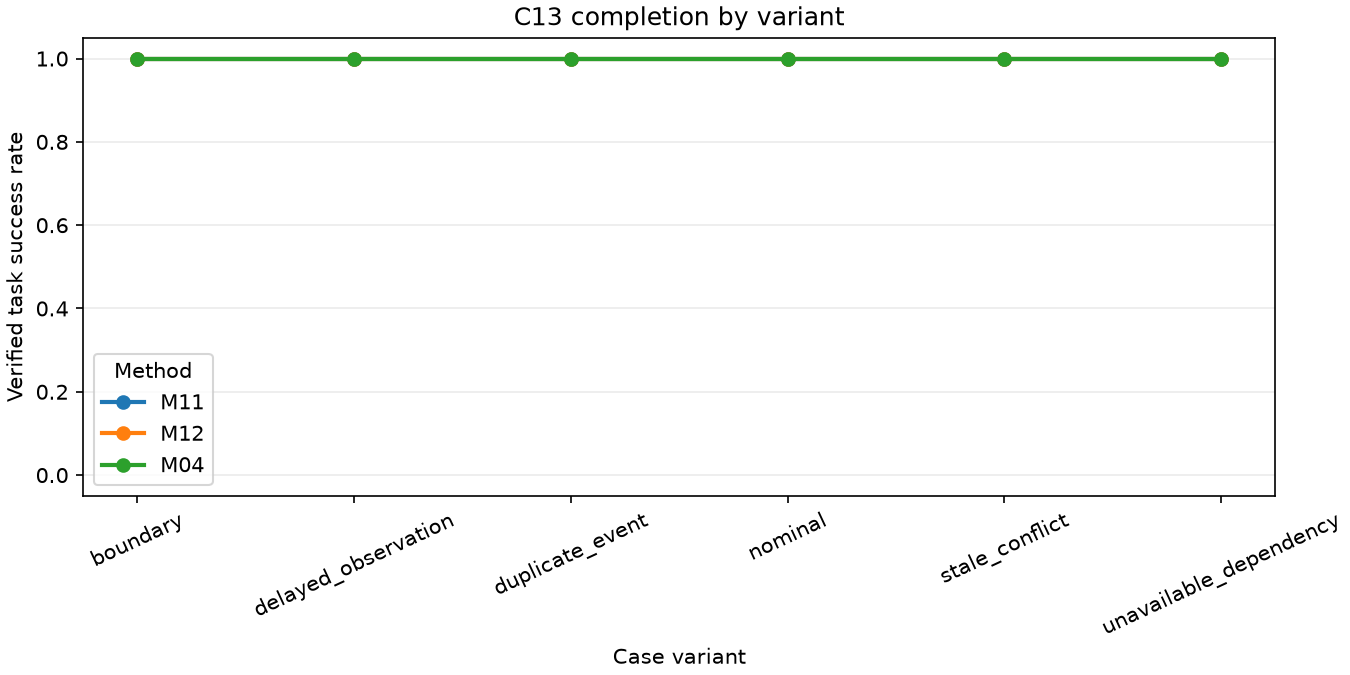

In [12]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified task success rate")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + " completion by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if False else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For the deliberation allocation comparator run on C13, for deliberation allocation, these bars show fresh task-postcondition outcomes for M11 and M12 on C13, with success encoded as 1 and failure as 0. Read the case and seed before comparing them. In the matched deliberation allocation comparison on C13, this controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks;

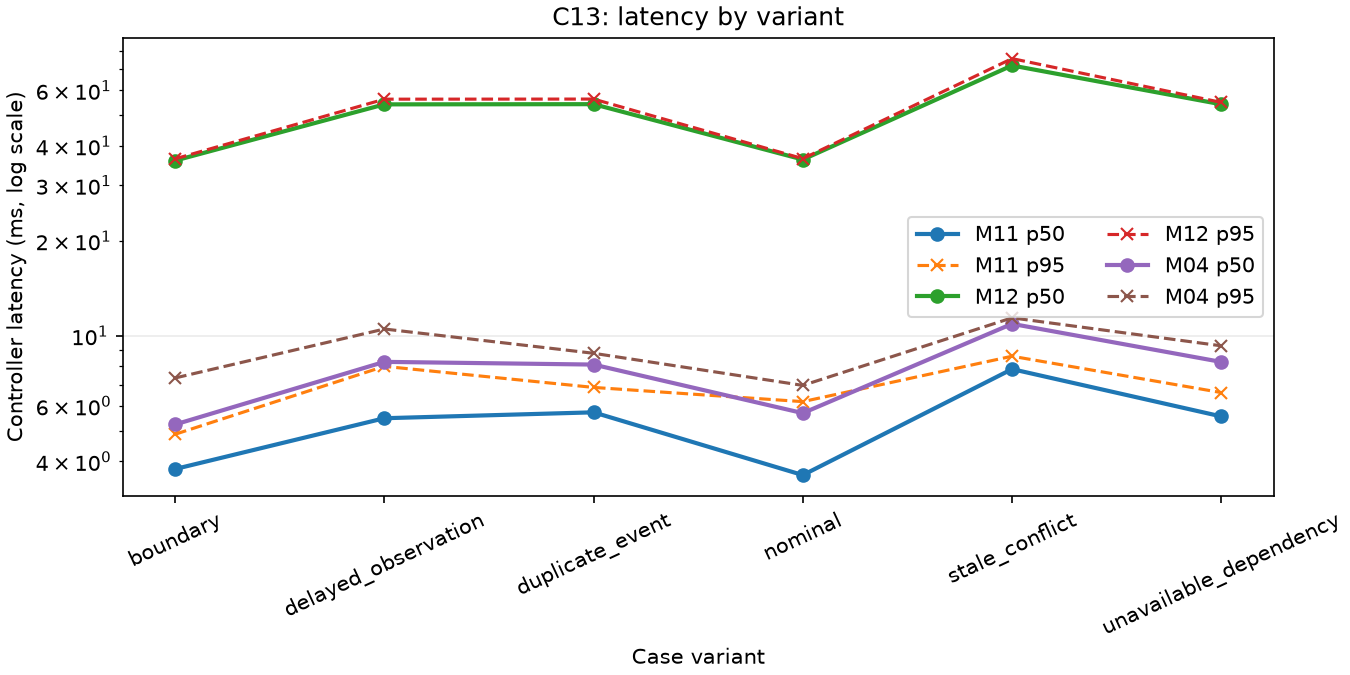

In [13]:
# Compare median and upper-tail controller time across the same case variants.
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
variants = sorted({variant for _, variant in case_records})
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(e['metrics']['controller_ms'] for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} p50')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} p95')
ax.set_yscale('log')
ax.set_ylabel("Controller latency (ms, log scale)")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + ": latency by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 3 deliberation allocation chart reads canonical M11/M04 records for C13, nominal variant and seed 40000 after the data boundary verifies their hashes. A fitted routing label is not a completed task; inspect the policy's measured result.

Chart 3, lesson level 3, summarizes family-level controller latency alongside task completion for C13.

## Results

**Answer:** The deliberation allocation level-3 comparison contains 2 fresh policy episodes plus 1 XGBoost M04 comparator on C13; those 3 matched runs do not establish population-level superiority for deliberation allocation.

Within this deliberation allocation comparison (C13), the gate fit used 228 states with seven positive labels and selected threshold 1.01, meaning it never delegated through that gate. M12's other trigger is separate. In the matched deliberation allocation comparison on C13, report planner calls, latency and verified success; Within this deliberation allocation comparison (C13), A configured LLM is not evidence of useful deliberation;

## Summary

The fitted gate's decisions and outcomes, rather than its label, determine whether allocation helped.




## References
- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev) - [DPT](https://aclanthology.org/2025.acl-long.206/) - [VOC](https://arxiv.org/abs/1711.06892) - [DEFER](https://proceedings.mlr.press/v119/mozannar20b.html) - DPT-Agent. Code and FSM control with asynchronous language-model reasoning. https://aclanthology.org/2025.acl-long.206/